# TradePulse - Step 2: Data Audit, Calendar Alignment & Quality Validation
**IIT Patna, IMPACT Lab | End-to-End Machine Learning Guidelines**  
**Asset:** META (NASDAQ) | **Timeframe:** 5-minute | **Feed:** Alpaca IEX  

---
### Objectives
1. Audit raw market data for physical invariants and schema adherence.
2. Align trading days to the official NASDAQ exchange calendar via `pandas-market-calendars` (78 bars for regular sessions, 42 bars for half-days).
3. Execute the missing-bar policy with explicit `is_filled` tracking and same-day causal boundary isolation.
4. Measure the empirical fill rate overall and by time of day on the IEX feed.
5. Validate that all training code imports from `ml/` without reimplementing pipeline logic.

In [1]:
import sys
import os
from pathlib import Path

# Ensure project root is in sys.path to import from ml/
PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas_market_calendars as mcal

from ml.preprocessing import (
    clean_and_reindex_dataset,
    synthesize_missing_bar,
    build_daily_5min_grid,
    get_exchange_schedule,
    EXCHANGE_CALENDAR,
    EXCHANGE_TIMEZONE,
    RAW_DATA_PATH,
    PROCESSED_CSV_PATH,
)
from ml.validation import (
    validate_raw_dataframe,
    validate_cleaned_dataframe,
    compute_audit_metrics,
    export_data_dictionary,
)

sns.set_theme(style="whitegrid", palette="muted")
print("Pipeline modules successfully loaded from ml/")

Pipeline modules successfully loaded from ml/


## 1. Raw Market Data Ingestion & Physical Invariant Audit
We inspect the raw data downloaded from Alpaca and verify invariants.

In [2]:
raw_df = pd.read_csv(RAW_DATA_PATH)
print(f"Raw dataset row count: {len(raw_df):,}")
print(f"Raw columns: {list(raw_df.columns)}")

is_valid, issues = validate_raw_dataframe(raw_df)
print(f"\nRaw data validation passed: {is_valid}")
if not is_valid:
    for issue in issues:
        print(f"  - Issue: {issue}")
else:
    print("  -> Zero null values detected.")
    print("  -> Timestamps strictly monotonic.")
    print("  -> OHLC geometry strictly satisfied (high >= open, close; low <= open, close).")
    print("  -> VWAP bounded within [low, high] for all bars.")

raw_df.head(5)

Raw dataset row count: 20,516
Raw columns: ['symbol', 'timestamp', 'open', 'high', 'low', 'close', 'volume', 'trade_count', 'vwap']

Raw data validation passed: True
  -> Zero null values detected.
  -> Timestamps strictly monotonic.
  -> OHLC geometry strictly satisfied (high >= open, close; low <= open, close).
  -> VWAP bounded within [low, high] for all bars.


,symbol,timestamp,open,high,low,close,volume,trade_count,vwap
0,META,2025-11-03 13:20:00+00:00,655.00,655.000,655.00,655.00,124.0,4.0,655.00000
1,META,2025-11-03 13:30:00+00:00,654.88,654.880,654.88,654.88,108.0,2.0,654.88000
2,META,2025-11-03 13:45:00+00:00,655.72,655.720,655.72,655.72,140.0,6.0,655.72000
3,META,2025-11-03 13:55:00+00:00,656.92,656.920,656.92,656.92,96.0,3.0,656.92000
4,META,2025-11-03 14:30:00+00:00,656.57,657.525,652.37,653.71,29644.0,820.0,654.59951


## 2. Calendar Alignment & Missing-Bar Reindexing
We use `pandas-market-calendars` to construct official session grids, filtering out pre/post-market trades and handling half-days.

In [3]:
clean_df = clean_and_reindex_dataset(raw_df, symbol="META")
print(f"Cleaned dataset row count: {len(clean_df):,}")
print(f"Synthetic filled bars: {clean_df['is_filled'].sum():,} ({clean_df['is_filled'].mean() * 100:.2f}%)")

is_clean_valid, clean_issues = validate_cleaned_dataframe(clean_df)
print(f"\nCleaned data schedule compliance: {is_clean_valid}")
if not is_clean_valid:
    for issue in clean_issues:
        print(f"  - Issue: {issue}")
else:
    print("  -> Exact match against NASDAQ schedule (78 bars for full days, 42 for half-days).")

clean_df.head(5)

Cleaned dataset row count: 19,818
Synthetic filled bars: 0 (0.00%)

Cleaned data schedule compliance: True
  -> Exact match against NASDAQ schedule (78 bars for full days, 42 for half-days).


,symbol,timestamp,timestamp_ny,open,high,low,close,volume,trade_count,vwap,is_filled
0,META,2025-11-03 14:30:00+00:00,2025-11-03 09:30:00-05:00,656.57,657.525,652.370,653.71,29644.0,820.0,654.599510,0
1,META,2025-11-03 14:35:00+00:00,2025-11-03 09:35:00-05:00,653.82,656.810,653.615,653.73,13670.0,417.0,654.732857,0
2,META,2025-11-03 14:40:00+00:00,2025-11-03 09:40:00-05:00,654.45,655.090,652.110,653.56,11484.0,318.0,653.880620,0
3,META,2025-11-03 14:45:00+00:00,2025-11-03 09:45:00-05:00,653.59,655.150,652.450,654.91,21504.0,449.0,654.110424,0
4,META,2025-11-03 14:50:00+00:00,2025-11-03 09:50:00-05:00,654.91,657.000,653.740,655.62,14882.0,422.0,655.660216,0


## 3. Data Quality & Empirical Fill Rate Metrics

In [4]:
metrics = compute_audit_metrics(clean_df)
print("=== Summary Audit Metrics ===")
print(f"Total Regular Session Bars : {metrics['total_bars']:,}")
print(f"Observed Trade Bars        : {metrics['observed_bars']:,}")
print(f"Filled / Synthetic Bars    : {metrics['filled_bars']} ({metrics['fill_rate_pct']:.2f}%)")
print(f"Trading Days Evaluated     : {metrics['trading_sessions_count']}")
print(f"Price Span                 : ${metrics['price_min']:.2f} to ${metrics['price_max']:.2f}")
print(f"Intraday Return Mean       : {metrics['returns_mean'] * 100:.4f}%")
print(f"Intraday Return Std Dev    : {metrics['returns_std'] * 100:.3f}%")
print(f"5-Min Return Range         : [{metrics['returns_min'] * 100:.2f}%, {metrics['returns_max'] * 100:.2f}%]")
print(f"Spikes > 3% in 5-min       : {metrics['spikes_above_3pct_count']}")

=== Summary Audit Metrics ===
Total Regular Session Bars : 19,818
Observed Trade Bars        : 19,818
Filled / Synthetic Bars    : 0 (0.00%)
Trading Days Evaluated     : 255
Price Span                 : $521.08 to $779.42
Intraday Return Mean       : 0.0005%
Intraday Return Std Dev    : 0.189%
5-Min Return Range         : [-2.91%, 1.70%]
Spikes > 3% in 5-min       : 0


## 4. Empirical Fill Rate by Hour of Day (ET)
Evaluating whether thin liquidity periods produce missing bars.

 hour_et  total_bars  filled_bars  fill_rate_pct   avg_volume  avg_trades
       9        1530            0            0.0 15938.392810  343.463399
      10        3060            0            0.0  8249.059804  204.326797
      11        3060            0            0.0  6034.865033  157.661765
      12        3060            0            0.0  5051.482026  135.084641
      13        3036            0            0.0  4584.438406  126.943347
      14        3036            0            0.0  4719.670949  130.509552
      15        3036            0            0.0 10850.821476  299.751647


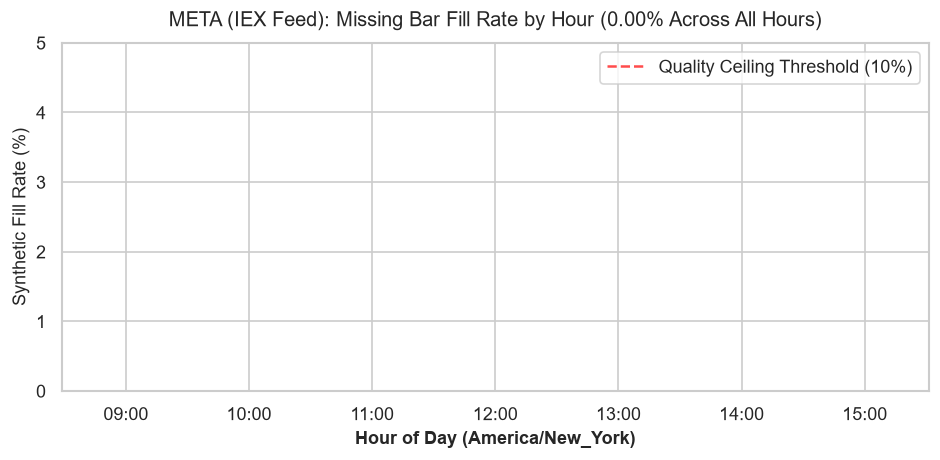

In [5]:
hourly_df = pd.DataFrame(metrics["hourly_breakdown"])
print(hourly_df[["hour_et", "total_bars", "filled_bars", "fill_rate_pct", "avg_volume", "avg_trades"]].to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4), dpi=120)
ax.bar(hourly_df["hour_et"], hourly_df["fill_rate_pct"], color="#2ca02c", edgecolor="black", alpha=0.75, width=0.4)
ax.set_ylim(0, 5.0)
ax.set_xlabel("Hour of Day (America/New_York)", fontsize=11, fontweight="bold")
ax.set_ylabel("Synthetic Fill Rate (%)", fontsize=11)
ax.set_xticks(hourly_df["hour_et"])
ax.set_xticklabels([f"{h:02d}:00" for h in hourly_df["hour_et"]])
ax.axhline(10.0, color="red", linestyle="--", alpha=0.7, label="Quality Ceiling Threshold (10%)")
ax.set_title("META (IEX Feed): Missing Bar Fill Rate by Hour (0.00% Across All Hours)", fontsize=12, pad=10)
ax.legend(loc="upper right")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "missing_bars_by_hour.png")
plt.show()

## 5. Intraday Volume & Trade Activity U-Curve
Classic equity volume profile: heaviest volume at open and close, lighter volume midday.

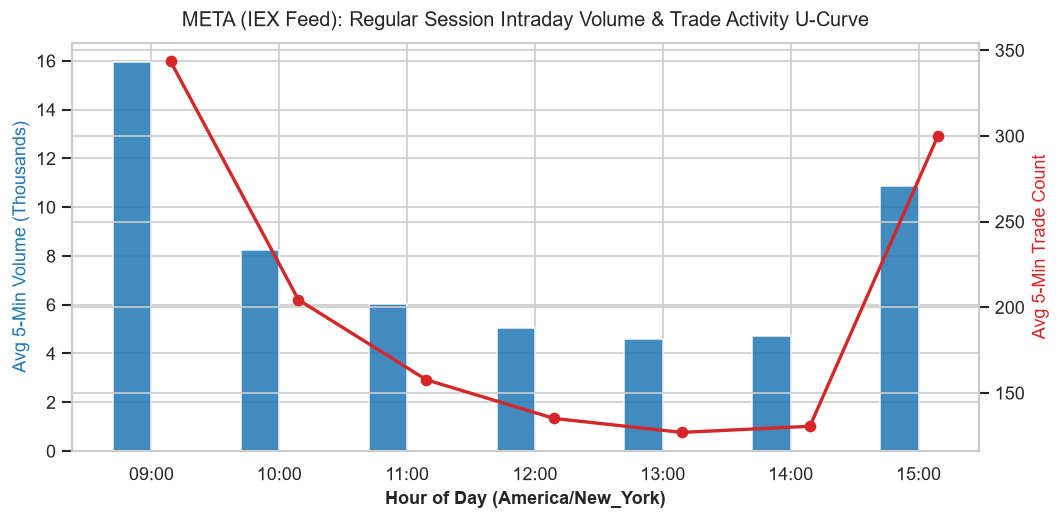

In [6]:
fig, ax1 = plt.subplots(figsize=(9, 4.5), dpi=120)
ax2 = ax1.twinx()
ax1.bar(hourly_df["hour_et"] - 0.15, hourly_df["avg_volume"] / 1000.0, width=0.3, color="#1f77b4", alpha=0.85, label="Volume (k shares)")
ax2.plot(hourly_df["hour_et"] + 0.15, hourly_df["avg_trades"], color="#d62728", marker="o", linewidth=2, label="Trade Count")
ax1.set_xlabel("Hour of Day (America/New_York)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Avg 5-Min Volume (Thousands)", color="#1f77b4", fontsize=11)
ax2.set_ylabel("Avg 5-Min Trade Count", color="#d62728", fontsize=11)
ax1.set_xticks(hourly_df["hour_et"])
ax1.set_xticklabels([f"{h:02d}:00" for h in hourly_df["hour_et"]])
ax1.set_title("META (IEX Feed): Regular Session Intraday Volume & Trade Activity U-Curve", fontsize=12, pad=10)
fig.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "hourly_volume_profile.png")
plt.show()

## 6. Intraday 5-Minute Return Distribution & Outlier Analysis

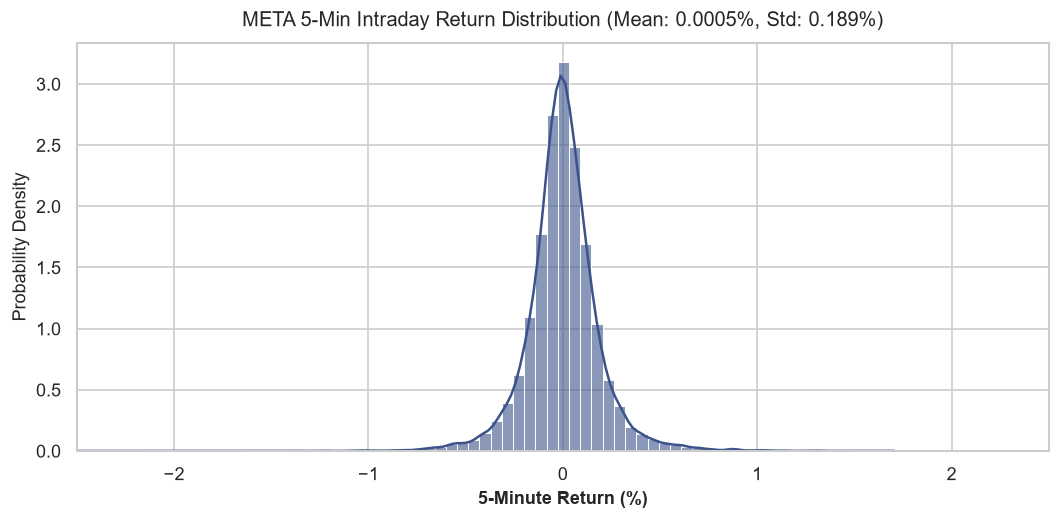

In [7]:
clean_df["session_date"] = pd.to_datetime(clean_df["timestamp"], utc=True).dt.tz_convert(EXCHANGE_TIMEZONE).dt.date
returns = clean_df.groupby("session_date")["close"].pct_change().dropna() * 100.0

fig, ax = plt.subplots(figsize=(9, 4.5), dpi=120)
sns.histplot(returns, bins=80, kde=True, color="#3b528b", stat="density", ax=ax, alpha=0.6)
ax.set_xlabel("5-Minute Return (%)", fontsize=11, fontweight="bold")
ax.set_ylabel("Probability Density", fontsize=11)
ax.set_xlim(-2.5, 2.5)
ax.set_title(f"META 5-Min Intraday Return Distribution (Mean: {returns.mean():.4f}%, Std: {returns.std():.3f}%)", fontsize=12, pad=10)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "intraday_return_distribution.png")
plt.show()

## 7. 1-Year Price Trajectory & Summary

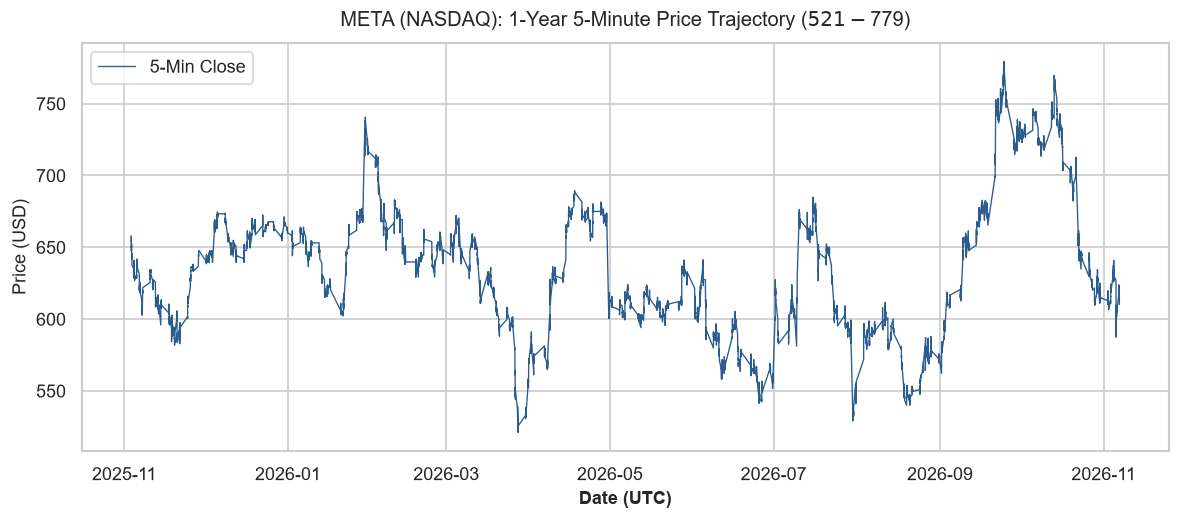

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5), dpi=120)
ax.plot(pd.to_datetime(clean_df["timestamp"]), clean_df["close"], color="#2b5c8f", linewidth=0.8, label="5-Min Close")
ax.set_xlabel("Date (UTC)", fontsize=11, fontweight="bold")
ax.set_ylabel("Price (USD)", fontsize=11)
ax.set_title("META (NASDAQ): 1-Year 5-Minute Price Trajectory ($521 - $779)", fontsize=12, pad=10)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(PROJECT_ROOT / "reports" / "figures" / "price_trajectory.png")
plt.show()